# Задача 4.15
# Монте Карло для двух точек в прямоугольнике

## Условие
В прямоугольнике $|x|\le20$, $|y|\le8$ независимо выбираются две равномерные точки. A — расстояние меньше 11; B — $|x_1-x_2|<14$. По $100000$ парам оценить $P(A)$ и $P(A\mid B)$.

## Теория с нуля и решение вручную
### 1. Что делает метод Монте Карло
Иногда аналитическая область сложна. Генерируем независимые опыты из нужного распределения, в каждом проверяем событие, затем используем частоту. Равномерная точка прямоугольника получается из независимых $X\sim U(-20,20)$ и $Y\sim U(-8,8)$. Все четыре координаты двух точек независимы.

### 2. Формулы событий и знаменатель
Расстояние по теореме Пифагора:
$$d=\sqrt{(x_1-x_2)^2+(y_1-y_2)^2}.$$
Проверяем $A=\{(x_1-x_2)^2+(y_1-y_2)^2<121\}$ и $B=\{|x_1-x_2|<14\}$. Из $A$ следует $|x_1-x_2|<11<14$, поэтому $A\subset B$. Значит,
$$\widehat P(A)=N_A/100000,\qquad\widehat P(A\mid B)=N_A/N_B.$$
Общая формула через пересечение даёт тот же результат. Важно использовать один и тот же набор пар для обоих ответов.

### 3. Ручная проверка через плотность разности
Для двух независимых равномерных координат на отрезке длины $L$ модуль разности $D$ имеет плотность $f_D(t)=2(L-t)/L^2$, $0<t<L$. Это получается из двух полос в квадрате: разность ближе к нулю встречается чаще. Для прямоугольника шириной 40 и высотой 16 модули $D_x,D_y$ независимы. Поэтому
$$P(B)=1-\left(1-\frac{14}{40}\right)^2=\frac{231}{400}=0.5775,$$
$$P(A)=\int_0^{11}\frac{2(40-u)}{40^2}\left[\frac{2\sqrt{121-u^2}}{16}-\frac{121-u^2}{16^2}\right]du.$$
В скобках стоит $P(D_y<\sqrt{121-u^2})$. Используем $\int_0^r\sqrt{r^2-u^2}\,du=\pi r^2/4$, $\int_0^ru\sqrt{r^2-u^2}\,du=r^3/3$ и интегралы степеней. При $L=40,H=16,r=11$:
$$P(A)=\frac{\pi LHr^2-\frac43(L+H)r^3+\frac12r^4}{L^2H^2}\approx0.36919947,\qquad P(A\mid B)=\frac{P(A)}{0.5775}\approx0.63930644.$$
Это дополнительная проверка моделирования, а не обязательная замена Монте Карло.

### 4. Округление
В тексте листка сказано округлить до одного знака после запятой, но приведены ответы с двумя. Покажем исходную частоту, округление до двух и до одного знака. Математически $0.37$ до одного знака даёт $0.4$, $0.64$ даёт $0.6$. Результаты разных запусков немного различаются.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

A: расстояние меньше 11: успехов 36888, знаменатель 100000
  частота = 0.36888000; ориентир 95%: [0.36588943; 0.37187057]
  теория = 0.36919947; разность = -0.00031947


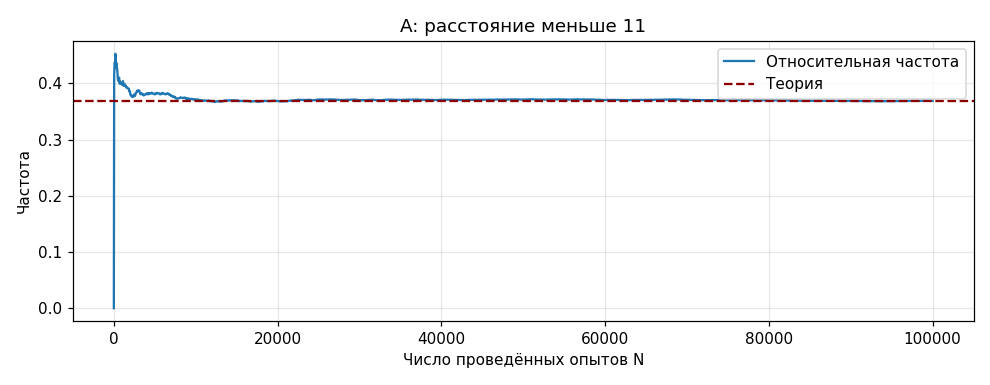

A при условии B: успехов 36888, знаменатель 57729
  частота = 0.63898561; ориентир 95%: [0.63506758; 0.64290363]
  теория = 0.63930644; разность = -0.00032083


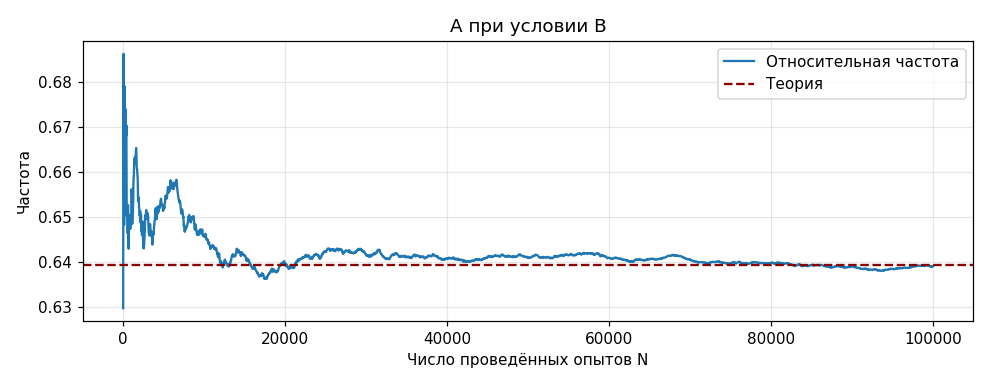

Проверка A является частью B: True
P(A): два знака 0.37; один знак 0.4
P(A|B): два знака 0.64; один знак 0.6


In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 100_000
x1 = rng.uniform(-20, 20, N)
y1 = rng.uniform(-8, 8, N)
x2 = rng.uniform(-20, 20, N)
y2 = rng.uniform(-8, 8, N)
dx = np.abs(x1-x2)
dy = np.abs(y1-y2)
A = dx**2+dy**2 < 11**2
B = dx < 14
L,H,r = 40,16,11
exact_A = (math.pi*L*H*r**2-4*(L+H)*r**3/3+r**4/2)/(L**2*H**2)
exact_B = 1-(1-14/L)**2
pA = report(A, 'A: расстояние меньше 11', exact_A)
pAB = report(A, 'A при условии B', exact_A/exact_B, B)
print('Проверка A является частью B:', np.all(~A | B))
for name, value in [('P(A)',pA), ('P(A|B)',pAB)]:
    print(f'{name}: два знака {value:.2f}; один знак {value:.1f}')
